In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Business Units

In [2]:
bu = pd.read_csv('business_units.csv')
bu.head()

,Business_Unit,Function,Public_Capacity,Source_URL,Verification_Class
0,LEO DESIGN,"Fashion design, pattern making, 3D visualization",Not publicly stated,https://www.el-sharnouby.com/,Public company fact
1,LEO TEX,Woven fabric manufacturing,Integrated textile manufacturing; exact capaci...,https://www.el-sharnouby.com/services,Public company fact
2,LEO PRODUCTION HUB,Garment manufacturing,"Up to 5,000 pieces/day",https://www.el-sharnouby.com/services,Public company fact
3,LEO PRINT,Textile and garment printing,"Up to 20,000 garments/day and 6,000 fabric met...",https://www.el-sharnouby.com/services,Public company fact
4,LEO MODA,"Retail, online and wholesale apparel brand",Delivery across Egypt; retail + wholesale chan...,https://leo.moda/,Public company fact


In [3]:
bu.shape

(5, 5)

# Case Briefs

In [4]:
df_case = pd.read_csv('case_Briefs.csv')

df_case.head(10)

,Card_No,Title,Business_Problem,Expected_Deliverable
0,1,Executive Sales & Profitability,"Revenue is growing, but management is unsure w...","Build an executive view of revenue, units, gro..."
1,2,Customer 360 & Retention,"The business has a growing customer base, but ...","Create customer segments using RFM/cohorts, re..."
2,3,Branch & Channel Performance,"Retail, online and wholesale operate different...","Compare channel growth, margin, returns, baske..."
3,4,Inventory & Demand Planning,Some SKUs tie up cash while other fast movers ...,"Perform ABC/XYZ analysis, stock turns, days of..."
4,5,Marketing Effectiveness,"Spend is distributed across platforms, but man...","Measure ROAS, CAC, CTR, conversion, attributed..."
5,6,Factory Production & Bottlenecks,Production orders show uneven efficiency and d...,"Analyze throughput, plan vs actual, reject rat..."
6,7,"Quality, Returns & Cost of Poor Quality",Customer returns and QC defects are not always...,"Build defect Pareto, quality loss, product/sta..."
7,8,Printing Performance & Downtime,Printing yield and rework vary by machine and ...,"Analyze machine yield, defect rate, reprint co..."
8,9,Supply Chain & Materials,Material availability and supplier reliability...,"Measure supplier lead time, on-time delivery, ..."
9,10,Integrated Management Story + Forecast,Leadership needs one connected story from mark...,Deliver a management dashboard/story that link...


In [5]:
df_case.shape

(10, 4)

# Customer Service

In [6]:
df_customer = pd.read_csv('Customer_Service.csv')

df_customer.head(2)

,Ticket_ID,Open_Date,Channel,Issue_Type,First_Response_Minutes,Resolution_Hours,Resolved,CSAT_1_to_5,Data_Class
0,TKT00001,2025-02-02,WhatsApp,Return request,6.5,9.3,Yes,2,Modeled customer service interaction
1,TKT00002,2024-01-01,Instagram,Order status,21.8,10.1,Yes,4,Modeled customer service interaction


In [7]:
df_customer.shape

(6500, 9)

In [8]:
df_customer.describe()

,First_Response_Minutes,Resolution_Hours,CSAT_1_to_5
count,6500.000000,6500.000000,6500.000000
mean,11.508138,17.442108,3.995231
std,9.147173,14.043986,1.142343
min,1.000000,0.200000,1.000000
25%,5.600000,8.000000,3.000000
50%,8.900000,15.800000,4.000000
75%,14.500000,23.700000,5.000000
max,109.300000,95.900000,5.000000


In [9]:
df_customer['Channel'].value_counts(normalize=True) *100

Channel
Instagram    25.630769
Phone        24.984615
WhatsApp     24.800000
Website      24.584615
Name: proportion, dtype: float64

In [10]:
df_customer['Issue_Type'].value_counts(normalize=True) *100

Issue_Type
Size guidance               20.723077
Order status                19.584615
General product question    16.646154
Exchange request            10.646154
Product quality             10.276923
Wholesale inquiry            9.215385
Return request               8.092308
Payment                      4.815385
Name: proportion, dtype: float64

In [11]:
df_customer['Resolved'].value_counts(normalize=True) *100

Resolved
Yes    95.076923
No      4.923077
Name: proportion, dtype: float64

In [12]:
# Avg First Response Time by Channel
df_customer.groupby('Channel')['First_Response_Minutes'].mean()

Channel
Instagram    11.670948
Phone        11.009544
Website      11.874593
WhatsApp     11.478908
Name: First_Response_Minutes, dtype: float64

In [13]:
# Avg Hours to Resolution by Channel
df_customer.groupby('Channel')['Resolution_Hours'].mean()

Channel
Instagram    17.735654
Phone        16.878202
Website      17.500375
WhatsApp     17.649069
Name: Resolution_Hours, dtype: float64

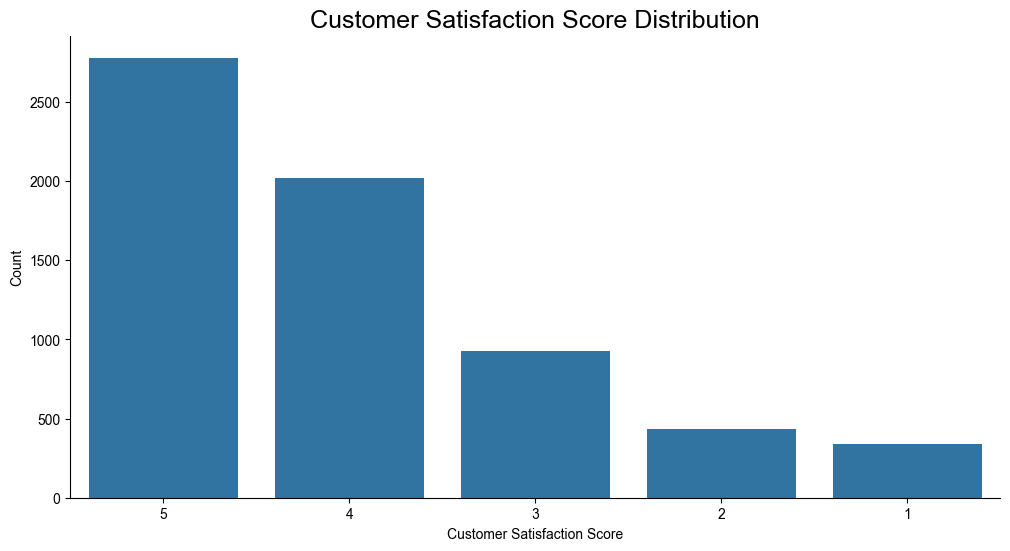

In [14]:
# Most score

plt.figure(figsize=(12,6))
sns.countplot(x='CSAT_1_to_5', data=df_customer, order=df_customer['CSAT_1_to_5'].value_counts().index)
sns.despine()
sns.set_style('whitegrid')
sns.set_palette('pastel')
sns.set_context('talk')
sns.set(font_scale=1.5)
plt.title('Customer Satisfaction Score Distribution')
plt.xlabel('Customer Satisfaction Score')
plt.ylabel('Count')

plt.show()

In [15]:
df_customer['CSAT_1_to_5'].value_counts(normalize=True) *100

CSAT_1_to_5
5    42.753846
4    31.076923
3    14.292308
2     6.692308
1     5.184615
Name: proportion, dtype: float64

In [16]:
df_customer.head(2)

,Ticket_ID,Open_Date,Channel,Issue_Type,First_Response_Minutes,Resolution_Hours,Resolved,CSAT_1_to_5,Data_Class
0,TKT00001,2025-02-02,WhatsApp,Return request,6.5,9.3,Yes,2,Modeled customer service interaction
1,TKT00002,2024-01-01,Instagram,Order status,21.8,10.1,Yes,4,Modeled customer service interaction


In [17]:
# Most Channel have CSAT score 5
df_customer[df_customer['CSAT_1_to_5'].isin([4, 5])]['Channel'].value_counts(normalize=True) * 100

Channel
Phone        25.484476
Instagram    25.442801
Website      24.609294
WhatsApp     24.463430
Name: proportion, dtype: float64

In [18]:
df_customer[df_customer['CSAT_1_to_5'].isin([1, 2])]['Channel'].value_counts(normalize=True) * 100

Channel
Instagram    26.813472
WhatsApp     25.777202
Website      24.481865
Phone        22.927461
Name: proportion, dtype: float64

# Customers

In [19]:
df_cus = pd.read_csv("Customers.csv")

df_cus.head(2)

,Customer_ID,Customer_Type,Governorate,Age_Band,Gender,Join_Date,Acquisition_Channel,Consent_Status,Data_Class
0,C00001,Retail,Dakahlia,45-54,Male,2026-02-22,Organic Social,Not opted-in,Modeled/anonymized training customer - not act...
1,C00002,Retail,Beheira,35-44,Male,2024-09-30,Direct / WhatsApp,Opted-in,Modeled/anonymized training customer - not act...


In [20]:
df_cus.shape

(30000, 9)

In [21]:
df_cus.describe()

,Customer_ID,Customer_Type,Governorate,Age_Band,Gender,Join_Date,Acquisition_Channel,Consent_Status,Data_Class
count,30000,30000,30000,30000,30000,30000,30000,30000,30000
unique,30000,2,13,6,4,1096,7,2,1
top,C29984,Retail,Alexandria,25-34,Female,2026-02-19,Direct / WhatsApp,Opted-in,Modeled/anonymized training customer - not act...
freq,1,28349,8415,10705,18931,45,6316,19187,30000


In [22]:
df_cus.isna().sum()

Customer_ID            0
Customer_Type          0
Governorate            0
Age_Band               0
Gender                 0
Join_Date              0
Acquisition_Channel    0
Consent_Status         0
Data_Class             0
dtype: int64

In [23]:
df_cus.head(2)

,Customer_ID,Customer_Type,Governorate,Age_Band,Gender,Join_Date,Acquisition_Channel,Consent_Status,Data_Class
0,C00001,Retail,Dakahlia,45-54,Male,2026-02-22,Organic Social,Not opted-in,Modeled/anonymized training customer - not act...
1,C00002,Retail,Beheira,35-44,Male,2024-09-30,Direct / WhatsApp,Opted-in,Modeled/anonymized training customer - not act...


In [24]:
df_cus['Acquisition_Channel'].value_counts(normalize=True) * 100

Acquisition_Channel
Direct / WhatsApp    21.053333
Organic Social       18.796667
Store Walk-in        17.473333
Paid Social          17.250000
Google Search        11.336667
Referral              8.586667
Wholesale Sales       5.503333
Name: proportion, dtype: float64

In [25]:
df_cus['Gender'].value_counts(normalize=True) * 100

Gender
Female           63.103333
Male             28.493333
Business          5.503333
Not specified     2.900000
Name: proportion, dtype: float64

In [26]:
df_cus['Customer_Type'].value_counts(normalize=True) * 100

Customer_Type
Retail       94.496667
Wholesale     5.503333
Name: proportion, dtype: float64

# Data Dictionary

In [27]:
df_data = pd.read_csv("Data_Dictionary.csv")

df_data.head(19)

,Table,Grain,Purpose,Real_vs_Modeled
0,Product_Master.csv,1 row per public product,Public product catalog master and public retai...,Public/verified master data
1,Business_Units.csv,1 row per company business unit,Group structure and public capacity facts,Public/verified facts
2,Locations.csv,1 row per channel / operating location,"Retail, online, wholesale, HQ and factory context",Public facts where available; exact factory ad...
3,Customers.csv,1 row per anonymized customer ID,Customer segmentation / retention / RFM,Modeled/anonymized training data
4,Sales_Transactions.csv,1 row per invoice line,"Sales, margin, returns, channel and product an...",Modeled transactions anchored to public produc...
5,Inventory_History.csv,month x location x product,"Inventory turns, stockouts, replenishment and ...",Modeled; intentionally contains NO forecast ou...
6,Marketing.csv,1 row per campaign,ROAS/CAC/conversion/attribution analysis,Modeled
7,Web_Traffic_Daily.csv,1 row per day,Digital funnel and conversion analysis,Modeled
8,Materials.csv,1 row per material,Material master,Modeled generic operational master
9,Product_BOM.csv,product x material,BOM / material requirements,Modeled


In [28]:
df_data.shape

(19, 4)

# Group Operations

In [29]:
CSV_PATH = "Group_Operations.csv"   # غيّر المسار حسب مكان الملف
LOW_EFF = 80                        # حد الكفاءة المنخفضة
HIGH_ISSUES = 8                     # حد المشاكل العالية في الشهر

pd.set_option("display.width", 200)

df = pd.read_csv(CSV_PATH, parse_dates=["Month"])
df = df.rename(columns={"Operational_Efficiency_Pct": "Eff", "Open_Issues_Count": "Issues"})
df["M"] = df["Month"].dt.month
# السنة المالية: أكتوبر -> سبتمبر (FY2026 = أكتوبر 2025 لسبتمبر 2026)
df["FY"] = np.where(df["M"] >= 10, df["Month"].dt.year + 1, df["Month"].dt.year)
df = df.sort_values(["Business_Unit", "Month"]).reset_index(drop=True)
df.head()

,Month,Business_Unit,Primary_KPI,Volume,Eff,Issues,Data_Class,M,FY
0,2023-10-01,LEO DESIGN,Designs_Completed,48,85.1,2,Modeled monthly operational summary using publ...,10,2024
1,2023-11-01,LEO DESIGN,Designs_Completed,72,77.8,0,Modeled monthly operational summary using publ...,11,2024
2,2023-12-01,LEO DESIGN,Designs_Completed,46,86.2,0,Modeled monthly operational summary using publ...,12,2024
3,2024-01-01,LEO DESIGN,Designs_Completed,66,80.2,4,Modeled monthly operational summary using publ...,1,2024
4,2024-02-01,LEO DESIGN,Designs_Completed,53,82.9,2,Modeled monthly operational summary using publ...,2,2024


## 1) فحص الداتا
**السؤال:** هل الداتا سليمة (قيم فاضية، تكرار، تغطية زمنية)؟

In [30]:
print("rows:", len(df), "| months:", df["Month"].nunique())
print("from", df["Month"].min().date(), "to", df["Month"].max().date())
print("missing values:", int(df.isna().sum().sum()))
print("duplicates (Month, Unit):", int(df.duplicated(["Month", "Business_Unit"]).sum()))
print("Data_Class:", df["Data_Class"].unique().tolist())

rows: 180 | months: 36
from 2023-10-01 to 2026-09-01
missing values: 0
duplicates (Month, Unit): 0
Data_Class: ['Modeled monthly operational summary using public business-unit structure']


## 2) المشكلة: أي وحدة فيها أكتر مشاكل؟
**السؤال:** مين بؤرة المشاكل، وهل كفاءته أقل كمان؟ (الكفاءة هنا مرجحة بالحجم)

In [31]:
g = df.groupby("Business_Unit")
issues_tbl = pd.DataFrame({
    "total_issues": g["Issues"].sum(),
    "avg_issues_per_month": g["Issues"].mean().round(1),
    f"months_issues>={HIGH_ISSUES}": g["Issues"].apply(lambda s: (s >= HIGH_ISSUES).sum()),
    "weighted_eff": g.apply(lambda x: np.average(x["Eff"], weights=x["Volume"])).round(1),
    f"%months_eff<{LOW_EFF}": g["Eff"].apply(lambda s: (s < LOW_EFF).mean() * 100).round(1),
})
issues_tbl["issues_share_%"] = (issues_tbl["total_issues"] / issues_tbl["total_issues"].sum() * 100).round(1)
issues_tbl.sort_values("total_issues", ascending=False)

C:\Users\Ctrl-Halim\AppData\Local\Temp\ipykernel_23592\3658988837.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "weighted_eff": g.apply(lambda x: np.average(x["Eff"], weights=x["Volume"])).round(1),


,total_issues,avg_issues_per_month,months_issues>=8,weighted_eff,%months_eff<80,issues_share_%
Business_Unit,,,,,,
LEO PRODUCTION HUB,219,6.1,13,85.4,11.1,30.4
LEO PRINT,139,3.9,6,85.9,16.7,19.3
LEO TEX,129,3.6,0,88.5,2.8,17.9
LEO DESIGN,124,3.4,0,85.6,16.7,17.2
LEO MODA,110,3.1,0,89.7,0.0,15.3


## 3) المشكلة: هل النمو ماشي مع الكفاءة؟
**السؤال:** كل سنة مالية، الحجم زاد ولا نقص، والكفاءة اتحسنت ولا نزلت؟

In [32]:
fy = df.groupby(["Business_Unit", "FY"]).agg(
    volume=("Volume", "sum"), eff=("Eff", "mean"), issues=("Issues", "sum")).round(1)
fy["volume_growth_%"] = (fy.groupby(level=0)["volume"].pct_change() * 100).round(1)
fy["eff_change_pts"] = fy.groupby(level=0)["eff"].diff().round(1)
fy

volume   eff  issues  volume_growth_%  eff_change_pts
Business_Unit      FY                                                          
LEO DESIGN         2024      760  83.7      34              NaN             NaN
                   2025      761  85.8      44              0.1             2.1
                   2026      838  87.2      46             10.1             1.4
LEO MODA           2024   510545  89.2      26              NaN             NaN
                   2025   565872  90.6      41             10.8             1.4
                   2026   584172  89.0      43              3.2            -1.6
LEO PRINT          2024  1504339  86.3      36              NaN             NaN
                   2025  1547063  87.6      66              2.8             1.3
                   2026  1648619  84.0      37              6.6            -3.6
LEO PRODUCTION HUB 2024  1095292  86.3      79              NaN             NaN
                   2025  1014189  85.1      65             -7.4            -1.2
                   2026  1161930  85.7      75             14.6             0.6
LEO TEX            2024  1542250  89.2      53              NaN             NaN
                   2025  1591736  87.4      40              3.2            -1.8
                   2026  1403705  89.7      36            -11.8             2.3

## 4) المشكلة: آخر 6 شهور، الأداء بيتحسن ولا بيسوء؟
**السؤال:** نقارن بالـ 6 شهور اللي قبلها، **وكمان بنفس الفترة من السنة اللي فاتت**.
المقارنة الثانية أدق لأنها بتشيل أثر المواسم.

In [33]:
n = 6
last_end = df["Month"].max()
p_last = pd.date_range(end=last_end, periods=n, freq="MS")
p_prev = pd.date_range(end=p_last[0] - pd.offsets.MonthBegin(1), periods=n, freq="MS")
p_yoy = p_last - pd.DateOffset(years=1)

def period_avg(months):
    x = df[df["Month"].isin(months)].groupby("Business_Unit")
    return x["Volume"].mean(), x["Eff"].mean()

v_l, e_l = period_avg(p_last); v_p, e_p = period_avg(p_prev); v_y, e_y = period_avg(p_yoy)
recent = pd.DataFrame({
    "vol_vs_prev_%": ((v_l / v_p - 1) * 100).round(1),
    "vol_vs_last_year_%": ((v_l / v_y - 1) * 100).round(1),
    "eff_vs_prev_pts": (e_l - e_p).round(1),
    "eff_vs_last_year_pts": (e_l - e_y).round(1),
})
recent

,vol_vs_prev_%,vol_vs_last_year_%,eff_vs_prev_pts,eff_vs_last_year_pts
Business_Unit,,,,
LEO DESIGN,-8.7,6.7,3.9,4.6
LEO MODA,22.8,4.3,-1.5,-0.5
LEO PRINT,-19.8,-6.2,-3.2,-3.4
LEO PRODUCTION HUB,-11.9,-0.1,7.0,5.0
LEO TEX,-1.4,-14.5,1.7,5.7


## 5) المشكلة: أي وحدة اتجاهها العام نازل؟
**السؤال:** الميل الخطي لكل وحدة (حجم، كفاءة، مشاكل) لكل شهر.

In [34]:
rows = []
for u, gdf in df.groupby("Business_Unit"):
    x = np.arange(len(gdf))
    rows.append({
        "Business_Unit": u,
        "volume_trend_%/month": round(np.polyfit(x, gdf["Volume"], 1)[0] / gdf["Volume"].mean() * 100, 2),
        "eff_trend_pts/month": round(np.polyfit(x, gdf["Eff"], 1)[0], 3),
        "issues_trend/month": round(np.polyfit(x, gdf["Issues"], 1)[0], 3),
    })
trend_tbl = pd.DataFrame(rows).set_index("Business_Unit")
trend_tbl

,volume_trend_%/month,eff_trend_pts/month,issues_trend/month
Business_Unit,,,
LEO DESIGN,0.38,0.140,0.050
LEO MODA,0.72,-0.030,0.040
LEO PRINT,0.19,-0.138,0.022
LEO PRODUCTION HUB,0.36,0.004,-0.007
LEO TEX,-0.39,-0.006,-0.056


## 6) المشكلة: الموسمية
**السؤال:** إمتى كل وحدة في الذروة وإمتى في الركود؟
المؤشر = متوسط الشهر ÷ المتوسط العام. ولو أكتر من شهر قريبين من الذروة، يبقى مفيش ذروة واحدة واضحة.

In [35]:
season = pd.DataFrame({u: gdf.groupby("M")["Volume"].mean() / gdf["Volume"].mean()
                       for u, gdf in df.groupby("Business_Unit")})

summary = pd.DataFrame({"peak_month": season.idxmax(), "peak_idx": season.max(),
                        "low_month": season.idxmin(), "low_idx": season.min()})
summary["swing_x"] = summary["peak_idx"] / summary["low_idx"]
summary["months_near_peak(±0.03)"] = [season.index[season[u] >= season[u].max() - 0.03].tolist()
                                      for u in season.columns]
display(season.round(2))
summary.round(2)

,LEO DESIGN,LEO MODA,LEO PRINT,LEO PRODUCTION HUB,LEO TEX
M,,,,,
1,1.14,0.82,1.09,0.89,0.99
2,1.13,0.73,0.80,1.17,0.85
3,0.90,0.96,1.24,0.96,0.96
4,0.99,1.07,1.12,0.98,1.03
5,0.93,1.15,1.07,1.07,0.98
6,1.14,1.13,0.77,0.89,1.00
7,1.18,1.21,1.08,0.91,1.05
8,0.87,1.13,0.74,1.16,0.92
9,0.92,0.90,0.95,1.10,1.04


,peak_month,peak_idx,low_month,low_idx,swing_x,months_near_peak(±0.03)
LEO DESIGN,7,1.18,12,0.85,1.38,[7]
LEO MODA,7,1.21,2,0.73,1.65,[7]
LEO PRINT,3,1.24,8,0.74,1.68,[3]
LEO PRODUCTION HUB,12,1.17,11,0.81,1.46,"[2, 8, 12]"
LEO TEX,10,1.14,2,0.85,1.34,[10]


## 7) المشكلة: هل الكفاءة بتتأثر بالمشاكل والحجم؟
**السؤال:** الارتباط داخل كل وحدة.

> n=36 فقط، فأي رقم تحت ±0.33 تقريباً مش دلالة إحصائية. اعتبره تلميح مش دليل.

In [36]:
rows = []
for u, gdf in df.groupby("Business_Unit"):
    rows.append({"Business_Unit": u,
                 "eff~issues": gdf["Eff"].corr(gdf["Issues"]),
                 "eff~volume": gdf["Eff"].corr(gdf["Volume"]),
                 "issues~volume": gdf["Issues"].corr(gdf["Volume"])})
within_corr = pd.DataFrame(rows).set_index("Business_Unit").round(2)
within_corr

,eff~issues,eff~volume,issues~volume
Business_Unit,,,
LEO DESIGN,-0.18,0.03,0.19
LEO MODA,-0.21,0.14,-0.31
LEO PRINT,-0.21,-0.06,0.10
LEO PRODUCTION HUB,-0.15,-0.23,0.23
LEO TEX,0.05,-0.29,-0.09


## 8) المشكلة: هل الوحدات مرتبطة ببعض؟
**السؤال:** ارتباط أحجام الوحدات، وبعدين مع تأخير زمني في سلسلة (تصميم ← أقمشة/طباعة ← إنتاج ← مبيعات).

In [37]:
pivot = df.pivot(index="Month", columns="Business_Unit", values="Volume")
display(pivot.corr().round(2))

chain = [("LEO TEX", "LEO PRODUCTION HUB"), ("LEO PRINT", "LEO PRODUCTION HUB"),
         ("LEO PRODUCTION HUB", "LEO MODA"), ("LEO DESIGN", "LEO PRINT")]
lag_tbl = pd.DataFrame(
    {f"{a} -> {b}": [round(float(pivot[a].corr(pivot[b].shift(-k))), 2) for k in range(4)]
     for a, b in chain},
    index=[f"lag {k}m" for k in range(4)]).T
lag_tbl

Business_Unit,LEO DESIGN,LEO MODA,LEO PRINT,LEO PRODUCTION HUB,LEO TEX
Business_Unit,,,,,
LEO DESIGN,1.00,-0.06,0.03,-0.12,0.05
LEO MODA,-0.06,1.00,0.20,0.09,0.02
LEO PRINT,0.03,0.20,1.00,0.05,0.11
LEO PRODUCTION HUB,-0.12,0.09,0.05,1.00,-0.07
LEO TEX,0.05,0.02,0.11,-0.07,1.00


,lag 0m,lag 1m,lag 2m,lag 3m
LEO TEX -> LEO PRODUCTION HUB,-0.07,-0.12,-0.12,-0.04
LEO PRINT -> LEO PRODUCTION HUB,0.05,0.18,0.17,0.11
LEO PRODUCTION HUB -> LEO MODA,0.09,-0.11,-0.13,0.24
LEO DESIGN -> LEO PRINT,0.03,-0.09,-0.06,0.07


## 9) المشكلة: أسوأ الشهور
**السؤال:** أنهي شهور كانت كفاءتها الأقل، وأنهي كان فيها أكتر مشاكل؟

In [38]:
cols = ["Month", "Business_Unit", "Volume", "Eff", "Issues"]
print("أقل كفاءة:")
display(df.nsmallest(8, "Eff")[cols].reset_index(drop=True))
print("أكتر مشاكل:")
df.nlargest(8, "Issues")[cols].reset_index(drop=True)

أقل كفاءة:


,Month,Business_Unit,Volume,Eff,Issues
0,2026-02-01,LEO PRINT,126614,73.5,8
1,2024-03-01,LEO DESIGN,65,74.4,7
2,2026-05-01,LEO PRINT,157178,74.4,7
3,2026-08-01,LEO PRODUCTION HUB,95683,75.9,6
4,2025-07-01,LEO PRINT,122538,76.0,6
5,2025-08-01,LEO TEX,127016,76.2,2
6,2025-05-01,LEO PRODUCTION HUB,67402,76.8,7
7,2026-01-01,LEO PRINT,143233,77.3,4


أكتر مشاكل:


,Month,Business_Unit,Volume,Eff,Issues
0,2024-03-01,LEO PRODUCTION HUB,105643,82.8,10
1,2025-04-01,LEO PRODUCTION HUB,100093,80.9,10
2,2026-05-01,LEO PRODUCTION HUB,105505,81.3,10
3,2025-09-01,LEO PRINT,132856,92.8,9
4,2023-10-01,LEO PRODUCTION HUB,78490,88.5,9
5,2024-01-01,LEO PRODUCTION HUB,106456,86.6,9
6,2024-05-01,LEO PRODUCTION HUB,118603,89.6,9
7,2024-06-01,LEO PRODUCTION HUB,91222,79.5,9


## 10) رسم: الكفاءة والمشاكل لكل وحدة
الخط = الكفاءة، والأعمدة = المشاكل المفتوحة، والخط الأحمر = حد الكفاءة المنخفضة.

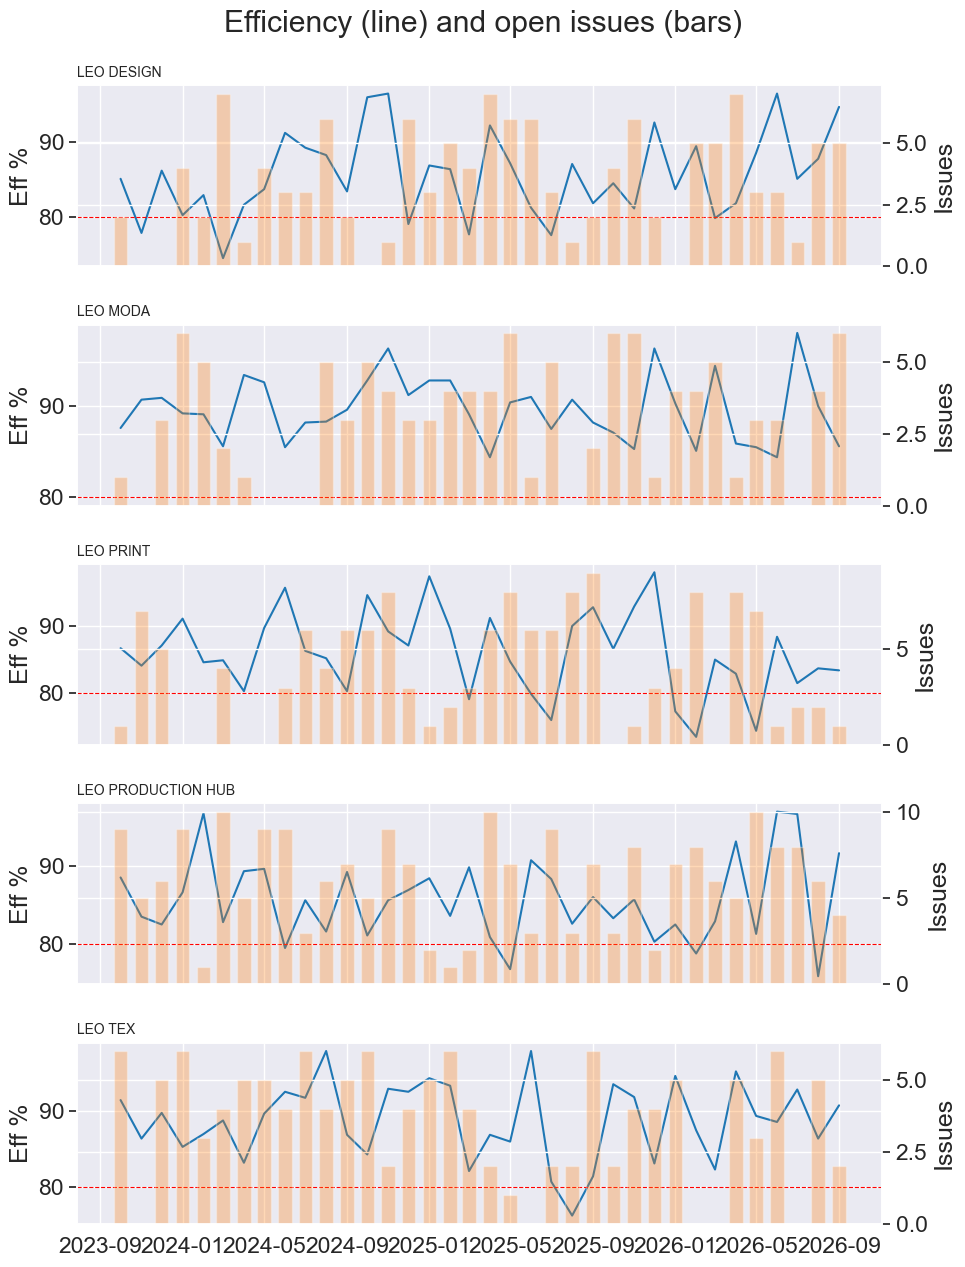

In [39]:
units = df["Business_Unit"].unique()
fig, axes = plt.subplots(len(units), 1, figsize=(10, 2.6 * len(units)), sharex=True)
for ax, u in zip(axes, units):
    gdf = df[df["Business_Unit"] == u]
    ax.plot(gdf["Month"], gdf["Eff"], color="tab:blue")
    ax.axhline(LOW_EFF, color="red", ls="--", lw=0.8)
    ax2 = ax.twinx()
    ax2.bar(gdf["Month"], gdf["Issues"], width=20, alpha=0.3, color="tab:orange")
    ax.set_title(u, fontsize=10, loc="left"); ax.set_ylabel("Eff %"); ax2.set_ylabel("Issues")
fig.suptitle("Efficiency (line) and open issues (bars)")
fig.tight_layout(); plt.show()

## 11) رسم: الموسمية

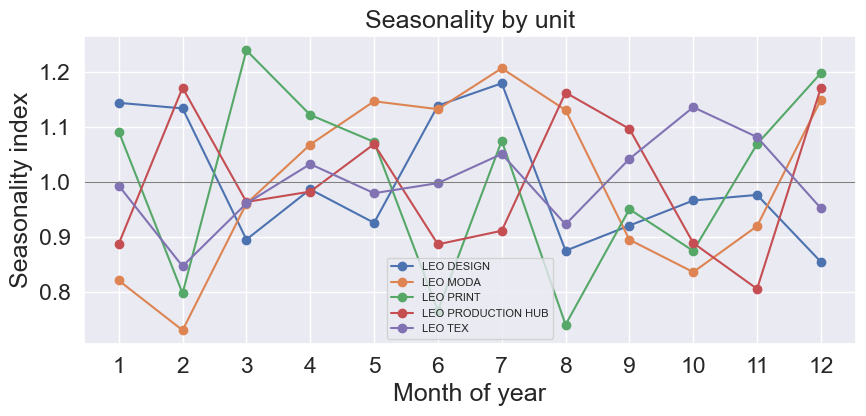

In [40]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for u in season.columns:
    ax.plot(season.index, season[u], marker="o", label=u)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month of year"); ax.set_ylabel("Seasonality index")
ax.set_title("Seasonality by unit"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 12) رسم: نمو الحجم بالسنة المالية
أول سنة مالية = 100 لكل وحدة.

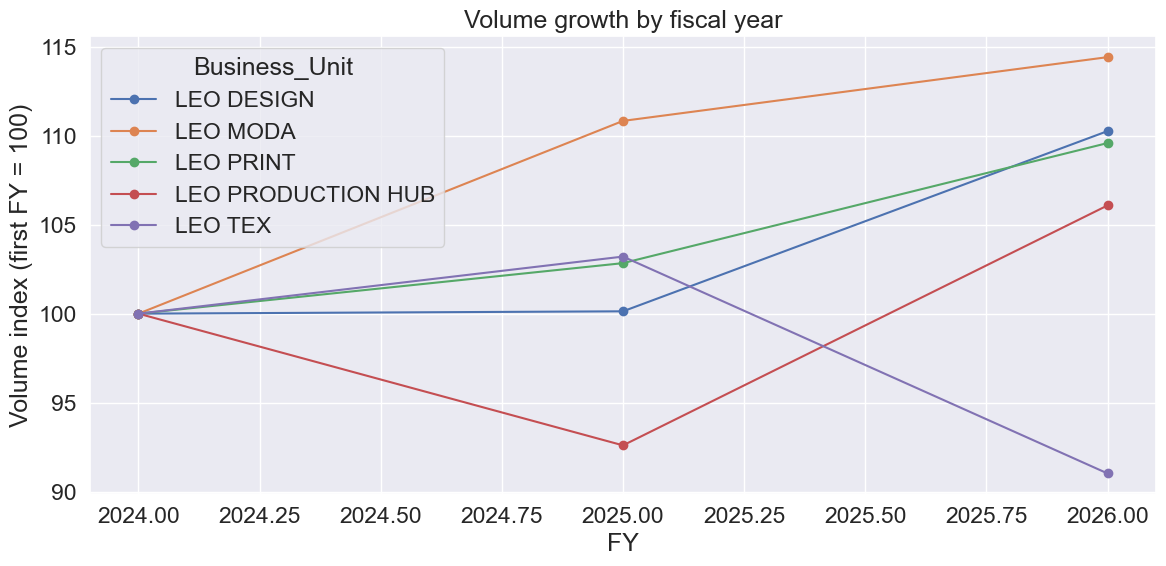

In [41]:
fy_vol = df.groupby(["Business_Unit", "FY"])["Volume"].sum().unstack()
(fy_vol.div(fy_vol.iloc[:, 0], axis=0) * 100).T.plot(marker="o", figsize=(12, 6))
plt.ylabel("Volume index (first FY = 100)"); plt.title("Volume growth by fiscal year")
plt.tight_layout(); plt.show()

# Inventory History

In [42]:
df_inv = pd.read_csv("Inventory_History.csv")

df_inv.head(2)

,Snapshot_Month,Location_ID,Location_Name,Product_ID,SKU,Product_Name,Opening_Stock,Received_Qty,Sold_Qty,Returned_Qty,Damaged_Qty,Closing_Stock,Avg_Daily_Sales_90D,Safety_Stock_Units,Reorder_Point_Units,Supplier_Lead_Time_Days,Days_of_Cover,Stockout_Days_In_Month,Data_Class
0,2023-10-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,176,39,42,3,0,176,1.38,5,12,5,127.5,0,Modeled inventory history - no forecast column...
1,2023-11-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,176,65,62,4,1,182,1.71,23,59,21,106.4,0,Modeled inventory history - no forecast column...


In [43]:
df_inv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6372 entries, 0 to 6371
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Snapshot_Month           6372 non-null   object 
 1   Location_ID              6372 non-null   object 
 2   Location_Name            6372 non-null   object 
 3   Product_ID               6372 non-null   object 
 4   SKU                      6372 non-null   object 
 5   Product_Name             6372 non-null   object 
 6   Opening_Stock            6372 non-null   int64  
 7   Received_Qty             6372 non-null   int64  
 8   Sold_Qty                 6372 non-null   int64  
 9   Returned_Qty             6372 non-null   int64  
 10  Damaged_Qty              6372 non-null   int64  
 11  Closing_Stock            6372 non-null   int64  
 12  Avg_Daily_Sales_90D      6372 non-null   float64
 13  Safety_Stock_Units       6372 non-null   int64  
 14  Reorder_Point_Units     

In [44]:
df_inv.describe()

,Opening_Stock,Received_Qty,Sold_Qty,Returned_Qty,Damaged_Qty,Closing_Stock,Avg_Daily_Sales_90D,Safety_Stock_Units,Reorder_Point_Units,Supplier_Lead_Time_Days,Days_of_Cover,Stockout_Days_In_Month
count,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000
mean,358.662586,257.446014,260.607188,5.843220,0.954175,362.854991,8.518817,63.247018,159.731481,11.387006,335.284401,0.187853
std,493.797621,451.562006,465.679225,14.663688,1.795573,510.997804,14.562623,122.996414,312.608413,5.702063,1147.483763,1.312087
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.040000,5.000000,5.000000,5.000000,0.000000,0.000000
25%,135.000000,25.000000,23.000000,0.000000,0.000000,133.000000,0.817500,5.000000,13.000000,7.000000,33.700000,0.000000
50%,222.000000,64.000000,56.000000,1.000000,0.000000,222.000000,1.840000,13.000000,33.000000,10.000000,96.150000,0.000000
75%,341.000000,264.250000,264.000000,4.000000,1.000000,339.250000,9.870000,61.000000,154.250000,14.000000,223.800000,0.000000
max,3696.000000,4011.000000,4500.000000,186.000000,18.000000,3789.000000,133.220000,1467.000000,3724.000000,21.000000,21175.000000,13.000000


In [45]:
df_inv.isna().sum()

Snapshot_Month             0
Location_ID                0
Location_Name              0
Product_ID                 0
SKU                        0
Product_Name               0
Opening_Stock              0
Received_Qty               0
Sold_Qty                   0
Returned_Qty               0
Damaged_Qty                0
Closing_Stock              0
Avg_Daily_Sales_90D        0
Safety_Stock_Units         0
Reorder_Point_Units        0
Supplier_Lead_Time_Days    0
Days_of_Cover              0
Stockout_Days_In_Month     0
Data_Class                 0
dtype: int64

# Sale Transactions

In [46]:
df_sales = pd.read_csv("Sales_Transactions.csv")

df_sales.head(2)

,Row_ID,Invoice_ID,Order_Date,Month_Key,Location_ID,Location_Name,Channel,Customer_ID,Customer_Type,Customer_Governorate,...,Estimated_COGS_EGP,Gross_Profit_EGP,Gross_Margin_Pct,Payment_Method,Returned,Return_Date,Return_Reason,Refund_Value_EGP,Quality_Related_Return,Data_Class
0,0,INV0000001,2024-05-11,2024-05,LOC002,LEO MODA Online Store,Online,C18976,Retail,Cairo,...,247.57,82.23,0.2493,Wallet,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
1,1,INV0000002,2025-07-31,2025-07,LOC001,LEO MODA - Sidi Bishr Store,Retail,C22543,Retail,Alexandria,...,163.31,67.89,0.2936,Card,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...


In [47]:
df_sales.shape

(180000, 30)

In [48]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Row_ID                  180000 non-null  int64  
 1   Invoice_ID              180000 non-null  object 
 2   Order_Date              180000 non-null  object 
 3   Month_Key               180000 non-null  object 
 4   Location_ID             180000 non-null  object 
 5   Location_Name           180000 non-null  object 
 6   Channel                 180000 non-null  object 
 7   Customer_ID             180000 non-null  object 
 8   Customer_Type           180000 non-null  object 
 9   Customer_Governorate    180000 non-null  object 
 10  Product_ID              180000 non-null  object 
 11  SKU                     180000 non-null  object 
 12  Product_Name            180000 non-null  object 
 13  Product_Family          180000 non-null  object 
 14  Size                

In [49]:
df_sales.isna().sum()

Row_ID                         0
Invoice_ID                     0
Order_Date                     0
Month_Key                      0
Location_ID                    0
Location_Name                  0
Channel                        0
Customer_ID                    0
Customer_Type                  0
Customer_Governorate           0
Product_ID                     0
SKU                            0
Product_Name                   0
Product_Family                 0
Size                           0
Quantity                       0
List_Price_EGP                 0
Discount_Pct                   0
Gross_Sales_EGP                0
Net_Sales_EGP                  0
Estimated_COGS_EGP             0
Gross_Profit_EGP               0
Gross_Margin_Pct               0
Payment_Method                 0
Returned                       0
Return_Date               171457
Return_Reason                  0
Refund_Value_EGP               0
Quality_Related_Return         0
Data_Class                     0
dtype: int

# Quality

In [50]:
df_q = pd.read_csv("Quality.csv")

df_q.head(2)

,QC_ID,Inspection_Date,Product_ID,Product_Name,Stage,Inspected_Qty,Passed_Qty,Rejected_Qty,Defect_Type,Root_Cause,Estimated_Loss_EGP,Data_Class
0,QC000001,2026-03-09,P049,Fuchsia - طقم تيشيرت وشورت اطفال صيفي,Fabric,40,39,1,NaN,No significant issue,239.99,Modeled QC inspection
1,QC000002,2025-09-21,P027,Girls' pajamas - I'm Just a girl,Finishing,629,613,16,Color Misalignment,Operator method,1689.62,Modeled QC inspection


In [51]:
df.isnull().sum()

Month            0
Business_Unit    0
Primary_KPI      0
Volume           0
Eff              0
Issues           0
Data_Class       0
M                0
FY               0
dtype: int64